# Project 1: Experiments (Task 5, and Task 6 if done)

This notebook is a skeleton. Keep its sections and fill them in.

- All agents are defined in `agents.py`. Import them from there; do not define agents in this notebook.
- Run every season with `play(agent, bay)` from `agents.py`.
- Document each step: what you run, why, and what you observe.
- The notebook must run from top to bottom without errors (Kernel, Restart and Run All).

In [8]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from fishing import FishingBay, ContextualBay, load_log, choices
from agents import play, RandomAgent, RandomContextualAgent  # add your own agents here

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 0. Your team logs

Put the JSON log of each team member next to this notebook and list the files below.

In [9]:
TEAM_LOG_FILES = [
    "fishing_log_decker.json",
    "fishing_log_doyen.json",
    "fishing_log_bouakli.json",
]
logs = [load_log(path) for path in TEAM_LOG_FILES]

# Example: the spots chosen and the catches of the first member in Season 1
# spots, catches = choices(logs[0], season=1)

## Example: one season played by the random agent

`FishingBay(season, seed)` creates a random bay. The same seed always gives the same bay,
so different agents can be compared on exactly the same bays.

In [10]:
bay = FishingBay(season=1, seed=0)
agent = RandomAgent(seed=0)
total = play(agent, bay)
print(f"Total catch: {total} kg over {bay.days} days")
print("Spots chosen:", [spot for spot, catch in bay.history])

Total catch: 136.2 kg over 30 days
Spots chosen: [4, 3, 2, 1, 1, 0, 0, 0, 0, 4, 3, 4, 2, 3, 4, 3, 3, 2, 2, 4, 1, 4, 3, 0, 1, 4, 2, 0, 3, 3]


## 1. Random bays

Evaluate every agent on at least 1000 random bays for each season (1, 2 and 3), and report the distribution of the results.

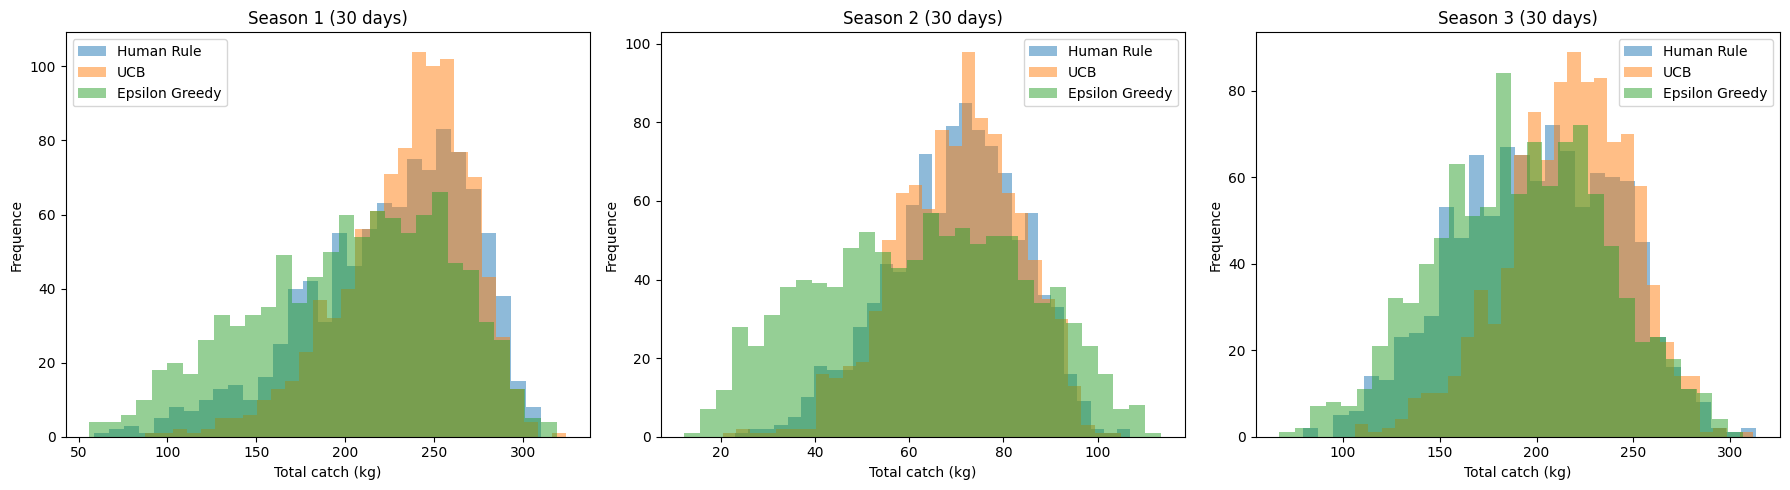

In [11]:
# Your code here
from agents import HumanRuleAgent, UCBAgent, EpsilonGreedyAgent
import matplotlib.pyplot as plt

n_bays = 1000
seasons = [1, 2, 3]

agents_dict = {
    "Human Rule": HumanRuleAgent(), "UCB" : UCBAgent(), "Epsilon Greedy" : EpsilonGreedyAgent()
}

results = {s: {name: [] for name in agents_dict} for s in seasons}

for s in seasons:
    for seed in range(n_bays):
        for name, agent in agents_dict.items():
            bay = FishingBay(season=s, seed=seed)
            total = play(agent, bay)
            results[s][name].append(total)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, s in enumerate(seasons):
    for name in agents_dict:
        axes[i].hist(results[s][name], bins=30, alpha=0.5, label=name)
    axes[i].set_title(f"Season {s} ({bay.days} days)")
    axes[i].set_xlabel("Total catch (kg)")
    axes[i].set_ylabel("Frequence")
    axes[i].legend()

plt.tight_layout()
plt.show()

## 2. Your team's bays

Run your agents on the bays played by your team members and compare with their results.
`FishingBay.from_log(log, season)` rebuilds the exact bay a member played, with the same catch on every day.

In [12]:
# Example: rebuild the Season 1 bay of the first member
# bay = FishingBay.from_log(logs[0], season=1)

# Your code here

print("Comparison on Decker's, Doyen's and Bouakli's bay")
for s in seasons:
    print(f"\nSeason {s}:")
    
    # Retrieve the actual human score from the JSON log (index s-1 because lists start at 0)
    decker_actual = logs[0]['rounds'][s-1]['total_kg']
    print(f"Decker's Score (Log) : {decker_actual} kg")
    doyen_actual = logs[1]['rounds'][s-1]['total_kg']
    print(f"Doyen's Score (Log) : {doyen_actual} kg")
    bouakli_actual = logs[2]['rounds'][s-1]['total_kg']
    print(f"Bouakli's Score (Log) : {bouakli_actual} kg")
    
    for name, agent in agents_dict.items():
        bay = FishingBay.from_log(logs[0], season=s)
        total = play(agent, bay)
        print(f"{name} : {total:.1f} kg")

Comparison on Decker's, Doyen's and Bouakli's bay

Season 1:
Decker's Score (Log) : 260.6 kg
Doyen's Score (Log) : 195.1 kg
Bouakli's Score (Log) : 130 kg
Human Rule : 264.6 kg
UCB : 262.6 kg
Epsilon Greedy : 177.7 kg

Season 2:
Decker's Score (Log) : 71.5 kg
Doyen's Score (Log) : 66.6 kg
Bouakli's Score (Log) : 70.3 kg
Human Rule : 80.4 kg
UCB : 74.9 kg
Epsilon Greedy : 90.3 kg

Season 3:
Decker's Score (Log) : 270.4 kg
Doyen's Score (Log) : 164.8 kg
Bouakli's Score (Log) : 177.4 kg
Human Rule : 275.8 kg
UCB : 269.9 kg
Epsilon Greedy : 229.9 kg


## 3. Seasons 2 and 3

Identify the best agent for Season 2 and for Season 3, and explain why.
`FishingBay(season, seed, days=..., shift_day=...)` lets you experiment with longer seasons.

In [ ]:
import numpy as np

n_bays_extended = 200
extended_days = 100
shift_day = 50

extended_results = {
    2: {name: [] for name in agents_dict},
    3: {name: [] for name in agents_dict}
}

print("--- Extended Season 2 (100 days) ---")
for seed in range(n_bays_extended):
    for name, agent in agents_dict.items():
        bay = FishingBay(season=2, seed=seed, days=extended_days)
        extended_results[2][name].append(play(agent, bay))

for name in agents_dict:
    print(f"{name} : Mean = {np.mean(extended_results[2][name]):.1f} kg")

print("\n--- Extended season 3 (100 days, changes at day 50) ---")
for seed in range(n_bays_extended):
    for name, agent in agents_dict.items():
        bay = FishingBay(season=3, seed=seed, days=extended_days, shift_day=shift_day)
        extended_results[3][name].append(play(agent, bay))

for name in agents_dict:
    print(f"{name} : Mean = {np.mean(extended_results[3][name]):.1f} kg")

--- Extended Season 2 (100 days) ---
Human Rule : Moyenne = 783.4 kg
UCB : Moyenne = 833.2 kg
Epsilon Greedy : Moyenne = 763.1 kg

--- Extended season 3 (100 days, changes at day 50) ---
Human Rule : Moyenne = 687.0 kg
UCB : Moyenne = 769.0 kg
Epsilon Greedy : Moyenne = 695.9 kg


## 4. One parameter

Study the effect of one parameter of one method.

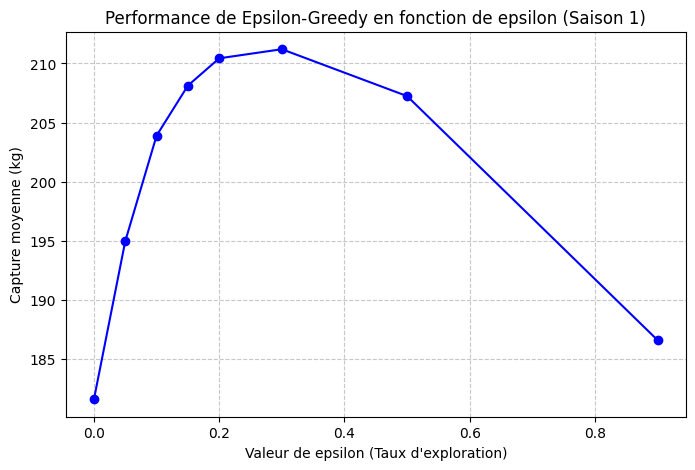

In [16]:
# The test will be done on the epsilon greedy agent
epsilon_values = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3, 0.5, 0.9]
n_bays_param = 500
avg_scores = []

for eps in epsilon_values:
    scores_eps = []
    agent = EpsilonGreedyAgent(epsilon=eps)
    for seed in range(n_bays_param):
        bay = FishingBay(season=1, seed=seed) 
        scores_eps.append(play(agent, bay))
    
    mean_score = np.mean(scores_eps)
    avg_scores.append(mean_score)

plt.figure(figsize=(8, 5))
plt.plot(epsilon_values, avg_scores, marker='o', linestyle='-', color='b')
plt.title("Performance de Epsilon-Greedy en fonction de epsilon (Saison 1)")
plt.xlabel("Valeur de epsilon (Taux d'exploration)")
plt.ylabel("Capture moyenne (kg)")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

## 5. Part IV (optional): contextual bay

`ContextualBay(seed)` lasts 300 days. Each morning, your agent receives the conditions
`x = [wind_kmh, waves_m, tide_m]` before choosing a spot. Contextual agents are subclasses of
`ContextualAgent` in `agents.py`.

In [ ]:
bay = ContextualBay(seed=0)
total = play(RandomContextualAgent(seed=0), bay)
print(f"Random contextual agent: {total} kg over {bay.days} days")

# Your code here